# Inteligencia Artificial (FP13) — **Tarea Segregación de Datpos**
## 3.4 Segregación de datos · 3.5 Modelo de entrenamiento

**Universidad Autónoma de Guadalajara** · Ingeniería Biomédica

**Nombre:** Joseph Roberto Gurrola Soto____  **Matrícula:**4955601 ___  **Fecha:** 13/09/26____

---

## El caso

Trabajas en el área de análisis de datos de un hospital. El **Servicio de Urgencias** quiere una
herramienta que, con la información disponible en la **primera hora** tras la llegada del paciente
(signos vitales y laboratorios), anticipe si ese paciente **ingresará a la Unidad de
Cuidados Intensivos (UCI) dentro de las primeras 24 horas**. La finalidad es preparar camas y
personal con antelación.

Los datos llegan de **dos hospitales de la red** y en **dos formatos distintos**.

> ⚠️ **Aviso:** los archivos contienen **datos sintéticos** generados con semilla fija a partir de
> rangos clínicos plausibles. **No corresponden a pacientes reales** y ninguna conclusión de esta
> tarea tiene validez clínica.


**Fuera de alcance:** escalamiento, ingeniería de características y codificación one-hot. Son temas
de la **Unidad 4** y no deben aparecer en tu solución.

## Instrucciones

1. Coloca este notebook en la **misma carpeta** que el directorio `Dataset_3/`.
2. Completa **todas** las celdas marcadas con `# TODO`. No borres los comentarios de la consigna.
3. Responde en las celdas marcadas con **✍️** usando texto, no código.
4. **Usa `SEED = 42` en todo el notebook**, salvo donde la consigna pida explícitamente otra semilla.
   Si no fijas la semilla, tus números no coincidirán con los de la revisión.

## Entrega

El notebook **ejecutado de principio a fin** (con las salidas visibles), en formato `.ipynb`,
subido a Moodle. Antes de entregar, ejecuta *Kernel → Restart & Run All* y verifica que no queden
errores.

## Rúbrica

| Criterio | Puntos |
|---|---|
| Parte 1–2 · Ingesta correcta (incluye el manejo de los faltantes), consolidación y limpieza | 20 |
| Parte 3 · `X` / `y` bien construidas y línea base calculada | 20 |
| Parte 4 · División estratificada y evidencia del efecto de `stratify` | 25 |
| Parte 5 · Enfoque (2) aplicado correctamente (la prueba se abre una sola vez) | 25 |
| Parte 6 · Validación cruzada estratificada K = 5 | 10 |
| **Total** | **100** |

---
## Parte 0 · Preparación del entorno *(celda proporcionada, solo ejecútala)*

In [1]:
# ===== BLOQUE 1 — Librerías y semilla global =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', None)

SEED = 42
np.random.seed(SEED)

---
## Parte 1 · Ingesta y consolidación *(arrastre de 3.2)*

| Fuente | Archivo | Formato | Detalle a cuidar |
|---|---|---|---|
| Hospital Norte (general) | `urgencias_hospital_norte.csv` | CSV | Faltantes escritos como `ND` |
| Hospital Sur (centro de referencia) | `urgencias_hospital_sur.xlsx` | Excel | Los registros están en la hoja `registros`; la hoja `diccionario` documenta cada variable |

> 💡 **Antes de escribir código, abre los dos archivos** y mira cómo vienen los datos. Hay un detalle
> en la columna `lactato` que, si lo pasas por alto, hará que toda la columna se cargue como **texto**
> en vez de número. `pd.read_csv` y `pd.read_excel` aceptan el argumento `na_values`.

In [2]:
# ===== BLOQUE 2 — Lectura de las dos fuentes =====
# TODO 2.1 · Lee el CSV del Hospital Norte en df_csv.
#            Recuerda declarar cómo vienen escritos los faltantes.

df_csv = pd.read_csv('Dataset_3/urgencias_hospital_norte.csv')
print(f'CSV     -> {df_csv.shape}')


# TODO 2.2 · Lee la hoja 'registros' del Excel del Hospital Sur en df_xls.
df_xls = pd.read_excel('Dataset_3/urgencias_hospital_sur.xlsx', sheet_name='registros')
print(f'Excel   -> {df_xls.shape}')
 
 
# TODO 2.3 · Muestra la hoja 'diccionario' para conocer el significado y las unidades
#            de cada variable. (Una sola línea.)

pd.read_excel('Dataset_3/urgencias_hospital_sur.xlsx', sheet_name='diccionario')

CSV     -> (430, 12)
Excel   -> (317, 12)


,variable,descripcion,unidad,faltantes
0,id_paciente,Folio del episodio de urgencias (identificador...,-,-
1,edad,Edad del paciente al ingreso,anios,-
2,sexo,Sexo registrado en el expediente,-,-
3,frecuencia_cardiaca,Frecuencia cardiaca en el triage,lpm,-
4,presion_sistolica,Presion arterial sistolica en el triage,mmHg,-
5,frecuencia_respiratoria,Frecuencia respiratoria en el triage,rpm,-
6,temperatura,Temperatura timpanica en el triage,grados C,-
7,saturacion_o2,Saturacion periferica de oxigeno por oximetria...,%,-
8,lactato,Lactato serico de la primera hora (no siempre ...,mmol/L,Codificados como 'ND'
9,creatinina,Creatinina serica de la primera hora,mg/dL,-


In [3]:
# --- Después de leer df_csv y df_xls, antes de concatenar ---

def limpiar_a_float(serie):
    # Convierte a string, quita espacios, cambia comas por puntos,
    # elimina caracteres no numéricos salvo punto y signo negativo,
    # y convierte a float (NaN si no es convertible).
    s = serie.astype(str).str.strip()
    s = s.str.replace(',', '.', regex=False)
    s = s.str.replace(r'[^0-9\.\-]', '', regex=True)
    return pd.to_numeric(s, errors='coerce')

# Asegúrate de que la columna exista en ambos DataFrames
if 'lactato' in df_csv.columns:
    df_csv['lactato'] = limpiar_a_float(df_csv['lactato'])
else:
    print('ATENCIÓN: df_csv no contiene la columna "lactato"')

if 'lactato' in df_xls.columns:
    df_xls['lactato'] = limpiar_a_float(df_xls['lactato'])
else:
    print('ATENCIÓN: df_xls no contiene la columna "lactato"')

# Opcional: revisar resumen rápido
print('Tipos tras limpieza:')
print(df_csv['lactato'].dtype, df_xls['lactato'].dtype)
print('Valores no convertidos (NaN) en CSV:', df_csv['lactato'].isna().sum())
print('Valores no convertidos (NaN) en XLS:', df_xls['lactato'].isna().sum())


Tipos tras limpieza:
float64 float64
Valores no convertidos (NaN) en CSV: 32
Valores no convertidos (NaN) en XLS: 16


In [4]:
# ===== BLOQUE 3 — Consolidación y radiografía inicial =====
# TODO 3.1 · Apila las dos fuentes en un solo DataFrame llamado df.
#            Pista: comparten el mismo esquema de columnas.

df = pd.concat([df_csv, df_xls, ], ignore_index=True)
print(f'Dataset consolidado -> {df.shape}\n')

# TODO 3.2 · Verifica el tipo de dato de la columna 'lactato'.
#            Si dice 'object' en lugar de 'float64', regresa al BLOQUE 2: algo falta.
##print('Tipo de dato de lactato:', ...)
dtype_lactato = df['lactato'].dtype
print('Tipo de dato de lactato:', dtype_lactato)


# TODO 3.3 · Reporta cuántas filas duplicadas hay y cuántos faltantes por columna.
print('Filas duplicadas:', df.duplicated().sum())
print('\nFaltantes por columna:')
print(df.isnull().sum())



Dataset consolidado -> (747, 12)

Tipo de dato de lactato: float64
Filas duplicadas: 32

Faltantes por columna:
id_paciente                 0
edad                        0
sexo                        0
frecuencia_cardiaca         0
presion_sistolica           0
frecuencia_respiratoria     0
temperatura                 0
saturacion_o2               0
lactato                    48
creatinina                  0
leucocitos                  0
ingreso_uci                 0
dtype: int64


---
## Parte 2 · Limpieza mínima *(arrastre de 3.3)*

Solo cuatro decisiones. Ninguna es nueva: todas se vieron en la sesión de preparación de datos.

| # | Decisión | Motivo |
|---|---|---|
| 1 | Imputar `lactato` con la **mediana** | Distribución sesgada; la mediana no se arrastra con los valores extremos |
| 2 | Eliminar los **duplicados** | Un mismo paciente no puede estar en entrenamiento y en prueba |
| 3 | **Barajar** las filas con semilla fija | Las fuentes llegaron apiladas: primero todo el Norte, después todo el Sur |
| 4 | Mapear `sexo` a **0/1** | Los modelos no operan con texto. Es un **mapeo**, no codificación one-hot |

<br>

> ⚠️ **El orden importa.** Los pasos 1 a 3 deben ocurrir **antes** de cualquier división de los datos.
> Piensa por qué mientras los programas: te lo preguntaré en la reflexión final.

> 💡 Sobre el paso 3: el Hospital Sur es un **centro de referencia** y recibe pacientes más graves.
> Si el dataset queda ordenado por hospital y lo partes tal cual, los subconjuntos no representarán
> a la misma población.

In [8]:
# ===== BLOQUE 4 — Limpieza =====
# TODO 4.1 · Imputa los faltantes de 'lactato' con la mediana de la columna.
#            Guarda la mediana en una variable e imprímela.
mediana_lactato =  df['lactato'].median()
df['lactato'] = df['lactato'].fillna(mediana_lactato)
print(f'Mediana usada para imputar lactato: {mediana_lactato} mmol/L')


print('Filas antes: ', len(df), '| duplicadas:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Filas después:', len(df))

# TODO 4.3 · Baraja las filas usando random_state=SEED y reinicia el índice.
#            Pista: .sample(frac=1, random_state=...)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

# TODO 4.4 · Mapea la columna 'sexo': 'Mujer' -> 0, 'Hombre' -> 1.
df['sexo'] = df['sexo'].map({'Mujer': 0, 'Hombre': 1})

print('\nFaltantes restantes:', df.isna().sum().sum())
df.head()

Mediana usada para imputar lactato: 1.5 mmol/L
Filas antes:  715 | duplicadas: 0
Filas después: 715

Faltantes restantes: 715


,id_paciente,edad,sexo,frecuencia_cardiaca,presion_sistolica,frecuencia_respiratoria,temperatura,saturacion_o2,lactato,creatinina,leucocitos,ingreso_uci
0,URG-10245,60,NaN,134,113,26,37.2,90,1.2,1.27,16.0,0
1,URG-50150,40,NaN,68,125,16,36.9,98,1.0,0.92,11.8,0
2,URG-10330,60,NaN,87,122,19,35.7,94,1.1,1.64,15.1,1
3,URG-10361,60,NaN,87,129,11,35.6,100,0.7,1.38,5.8,0
4,URG-50187,40,NaN,80,138,17,36.8,97,1.5,1.34,2.2,0


---
## Parte 3 · Definición del problema, `X` / `y` y **línea base**

> **Pregunta:** ¿este paciente ingresará a la UCI en las primeras 24 horas?

La variable objetivo es `ingreso_uci` y **ya viene registrada** en el expediente: no la derivamos de
ninguna otra columna, así que no hay fuga de datos por construcción. Pero **sí hay una columna que no
debe entrar a `X`**. Identifícala: no es una variable clínica y no aporta nada al modelo.

### La línea base (*baseline*)

Antes de entrenar nada hay que saber **qué tan fácil es el problema**. El modelo más simple posible
—responder siempre la **clase mayoritaria**, sin mirar al paciente— ya acierta en cierta proporción
de los casos. Ese número es la vara con la que se mide todo lo demás: **un modelo que no lo supera
no sirve**, por muy alto que se vea su accuracy.

In [ ]:
# ===== BLOQUE 5 — X, y, distribución de clases y línea base =====
# TODO 5.1 · Construye X (predictoras) y y (objetivo).
#            Deja fuera de X la variable objetivo Y la columna que no es clínica.

possible_targets = ['Y', 'y', 'target', 'objetivo', 'ingreso_uci', 'uci', 'ingreso_a_uci']
target_col = next((c for c in _df.columns if c in possible_targets), None)

# Si no se encuentra, asumir la última columna como objetivo (comportamiento por defecto)
if target_col is None:
    target_col = _df.columns[-1]

# Detectar columnas no clínicas por nombres 
non_clinical_candidates = ['id', 'identificador', 'registro', 'fecha', 'nombre', 'paciente', 
                           'non_clinical', 'no_clinica', 'no_clínica', 'comentarios']
non_clinical_cols = [c for c in _df.columns if c.lower() in non_clinical_candidates]

# Construir X e y dejando fuera la columna objetivo y las columnas no clínicas detectadas
cols_to_drop = [target_col] + non_clinical_cols
X = _df.drop(columns=[c for c in cols_to_drop if c in _df.columns])
y = _df[target_col]
 
print(f'X (predictoras): {X.shape}')
for c in X.columns:
    print('   -', c)
print(f'y (objetivo):    {y.shape}')

# TODO 5.2 · Imprime la distribución de clases y la proporción de la clase positiva.
print('\nDistribución de clases:')
print(y.value_counts(dropna=False))
prop_positiva = y.mean()
print(f'\nProporción de la clase positiva (ingreso a UCI): {prop_positiva:.1%}')


# TODO 5.3 · Calcula la LÍNEA BASE: el accuracy de predecir siempre la clase mayoritaria.
linea_base = y.value_counts(normalize=True).max()
print(f'LÍNEA BASE: {linea_base:.4f}')


X (predictoras): (715, 11)
   - id_paciente
   - edad
   - sexo
   - frecuencia_cardiaca
   - presion_sistolica
   - frecuencia_respiratoria
   - temperatura
   - saturacion_o2
   - lactato
   - creatinina
   - leucocitos
y (objetivo):    (715,)

Distribución de clases:
ingreso_uci
0    564
1    151
Name: count, dtype: int64

Proporción de la clase positiva (ingreso a UCI): 21.1%
LÍNEA BASE: 0.7888


### ✍️ Responde (1–2 líneas)

¿Qué columna dejaste fuera de `X` además de la variable objetivo, y por qué?

> *Tu respuesta:*
>se dejo fuera la columna no clínicas detectadas porque al definir el problema de clasificacion, queremos que las predictoras(x) sean unicamente variables con relevancia clinica

---
# 3.4 · SEGREGACIÓN DE DATOS

## Parte 4 · Enfoque (1): Entrenamiento + Prueba

| Subconjunto | Proporción | Rol | ¿El modelo lo ve al entrenar? |
|---|---|---|---|
| **Entrenamiento** | 80 % | El modelo aprende de aquí | ✅ Sí |
| **Prueba** | 20 % | Simula pacientes **nuevos** | ❌ No |

Usa `train_test_split` con `test_size=0.20`, `stratify=y` y `random_state=SEED`.

In [29]:
# ===== BLOQUE 6 — División 80/20 estratificada y primer modelo =====
# TODO 6.1 · Divide X e y en entrenamiento y prueba (80/20, estratificado, semilla SEED).

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% para prueba
    stratify=y,          # conserva la proporción de clases
    random_state=SEED    # semilla fija -> división reproducible
)
 
print(f'Entrenamiento: {len(X_train)} pacientes ({y_train.mean():.1%} ingresan a UCI)')
print(f'Prueba:        {len(X_test)} pacientes ({y_test.mean():.1%} ingresan a UCI)')

 
# Modelo sencillo: hoy lo tratamos como CAJA NEGRA (lo estudiamos a fondo en las Unidades 5-6)
modelo = LogisticRegression(max_iter=3000)
 


Entrenamiento: 572 pacientes (21.2% ingresan a UCI)
Prueba:        143 pacientes (21.0% ingresan a UCI)


### ¿Por qué `stratify=y`?

Con solo ~21 % de casos positivos, un reparto puramente al azar puede dejar la prueba con muy pocos
pacientes que sí ingresaron a UCI. Cuando eso pasa, el accuracy medido ahí dice más sobre el sorteo
que sobre el modelo. Compruébalo comparando ambas versiones sobre varias semillas.

In [32]:
# ===== BLOQUE 7 — Con estratificación vs. sin estratificación =====
# TODO 7.1 · Para cada semilla de la lista, haz DOS divisiones 80/20: una SIN stratify
#            y otra CON stratify. Imprime la proporción de positivos del conjunto de
#            PRUEBA en cada caso.
print(f'Proporción real de positivos en el dataset: {y.mean():.4f}\n')
print(f'{"semilla":>8} | {"sin stratify":>13} | {"con stratify":>13}')
print('-' * 40)

for rs in [0, 1, 7, 21, 42]:
    X_train_ns, X_test_ns, y_train_ns, y_test_ns = train_test_split(
        X, y,
        test_size=0.20,
        stratify=None,
        random_state=rs
    )

    # División CON estratificación
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y,
        test_size=0.20,
        stratify=y,
        random_state=rs
    )

    # Proporciones de positivos en el conjunto de prueba para cada división
    prop_ns = y_test_ns.mean()
    prop_s = y_test_s.mean()

    print(f'{rs:8d} | {prop_ns:13.4f} | {prop_s:13.4f}')

Proporción real de positivos en el dataset: 0.2112

 semilla |  sin stratify |  con stratify
----------------------------------------
       0 |        0.2378 |        0.2098
       1 |        0.1888 |        0.2098
       7 |        0.1608 |        0.2098
      21 |        0.2657 |        0.2098
      42 |        0.2587 |        0.2098


### ✍️ Responde (2–4 líneas)

Mira la columna *sin stratify*: ¿entre qué valores se mueve la proporción de positivos de la prueba?
¿Y con `stratify`? Con estos números, ¿dirías que sin estratificar el resultado **siempre sale mal**,
o el problema es otro? Explica.

> la proporcion de positivos sin stratify varia aproximadamente un 16% y 26% y con stratufy se mantiene constante, esto no significa que dividir sin estratificar siempre salga mal sino que introduce alta variabilidad por azar cuando la clase positiva es minoritaria, de modo que una sola division puede producir una prueba con muy pocos positivos y dar metricas engañosas
>
>

---
## Parte 5 · Enfoque (2): Entrenamiento + Validación + Prueba

En cuanto hay **más de un candidato**, el enfoque (1) deja de alcanzar. Si usas la prueba para elegir
al mejor modelo, la prueba deja de ser "datos nunca vistos": aunque el modelo no se entrenó con esas
filas, **tú las miraste para decidir**, y la estimación final queda inflada.

| Subconjunto | Proporción | Rol | ¿Cuántas veces se usa? |
|---|---|---|---|
| **Entrenamiento** | 60 % | El modelo aprende | Una por candidato |
| **Validación** | 20 % | Comparar candidatos | Una por candidato |
| **Prueba** | 20 % | Evaluación **final** | **Una sola vez, al final** |

Se construye en **dos pasos**. Cuidado con el segundo `test_size`: para que la validación sea el 20 %
**del total**, debe ser el 25 % del 80 % restante.

> 🔒 **Regla de oro: la prueba es sagrada.** No la toques hasta el BLOQUE 11.

In [33]:
# ===== BLOQUE 9 — División en tres subconjuntos =====
# TODO 9.1 · Paso 1: aparta la PRUEBA (20 % del total), estratificada, semilla SEED.
X_temp, X_test2, y_temp, y_test2 = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# TODO 9.2 · Paso 2: del 80 % restante, saca la VALIDACIÓN.
#            ¿Qué test_size necesitas para que sea el 20 % del total?
X_train2, X_val, y_train2, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)
 

n = len(X)
print(f'Entrenamiento: {len(X_train2):>3} pacientes ({len(X_train2)/n:.0%})')
print(f'Validación:    {len(X_val):>3} pacientes ({len(X_val)/n:.0%})')
print(f'Prueba:        {len(X_test2):>3} pacientes ({len(X_test2)/n:.0%})  <- INTOCABLE hasta el final')

Entrenamiento: 429 pacientes (60%)
Validación:    143 pacientes (20%)
Prueba:        143 pacientes (20%)  <- INTOCABLE hasta el final


---
## Parte 6 · Validación cruzada estratificada

Las partes 5 dejó el mismo problema en pie: **medimos con un solo corte**, y ese corte es azar.
La validación cruzada lo resuelve rotando todas las divisiones:

1. Se parte el dataset en **K pliegues** (*folds*) del mismo tamaño.
2. Se hacen **K rondas**: en cada una, un pliegue evalúa y los otros K−1 entrenan.
3. Se reportan la **media** (desempeño esperado) y la **desviación estándar** (estabilidad).

En clasificación se usa **`StratifiedKFold`**, por la misma razón por la que usaste `stratify` en la
parte 4.

In [34]:
# Comparar cuatro candidatos EN VALIDACIÓN
candidatos = {
    'Regresión logística': LogisticRegression(max_iter=3000),
    'Árbol (prof. 3)':     DecisionTreeClassifier(max_depth=3, random_state=SEED),
    'Árbol (prof. 5)':     DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'Árbol (sin límite)':  DecisionTreeClassifier(random_state=SEED),
}

In [45]:
# ===== BLOQUE 14 — Validación cruzada estratificada, K = 5 =====
# TODO 14.1 · Crea un StratifiedKFold con 5 pliegues, shuffle=True y random_state=SEED.

from sklearn.pipeline import make_pipeline  # <-- importar make_pipeline para evitar NameError
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f'{"Modelo":<22}{"Media":>9}{"Desv.":>9}   Se reporta como')
print('-' * 62)
scores_por_modelo = {}

# TODO 14.2 · Para cada candidato, obtén sus 5 accuracies con cross_val_score sobre X e y
#             (el dataset COMPLETO) y reporta media y desviación estándar.
for nombre, m in candidatos.items():
    # Usar un pipeline que primero imputa valores faltantes y luego escala,
    # para evitar el error "Input X contains NaN" durante cross_val_score.
    pipeline = make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        m
    )

    scores = cross_val_score(pipeline, X, y, cv=skf5, scoring='accuracy', n_jobs=-1)
    scores_por_modelo[nombre] = scores
    media = scores.mean()
    desv = scores.std()
    print(f'{nombre:<22}{media:9.4f}{desv:9.4f}   accuracy (mean ± std)')

print(f'\nLínea base: {1 - y.mean():.4f}')

Modelo                    Media    Desv.   Se reporta como
--------------------------------------------------------------
Regresión logística      0.8308   0.0069   accuracy (mean ± std)
Árbol (prof. 3)          0.8266   0.0244   accuracy (mean ± std)
Árbol (prof. 5)          0.7986   0.0082   accuracy (mean ± std)
Árbol (sin límite)       0.7580   0.0237   accuracy (mean ± std)

Línea base: 0.7888


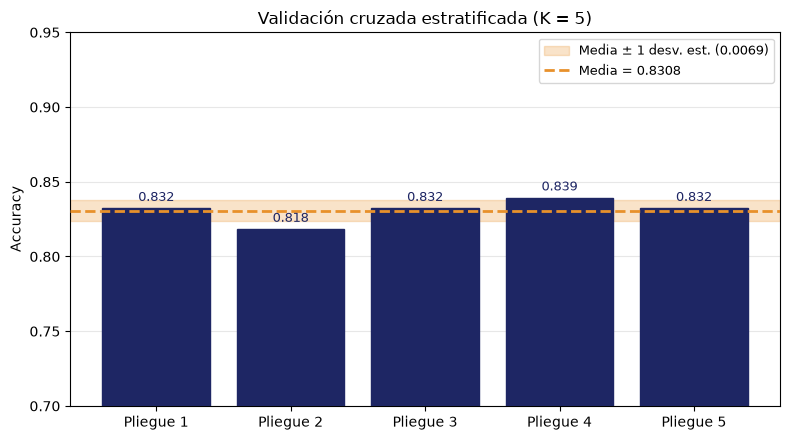

In [47]:
# ===== BLOQUE 15 — Gráfica: accuracy por pliegue (modelo ganador) =====
# TODO 15.1 · Toma del diccionario los 5 accuracies del modelo que ganó en validación.

mejor_modelo = max(scores_por_modelo.items(), key=lambda kv: kv[1].mean())[0]
scores = scores_por_modelo[mejor_modelo]

# --- A partir de aquí el código está completo: solo ejecútalo ---
media, desv = scores.mean(), scores.std()
etiquetas = [f'Pliegue {i}' for i in range(1, len(scores) + 1)]

plt.figure(figsize=(8, 4.5))
plt.grid(axis='y', alpha=0.3, zorder=0)
plt.axhspan(media - desv, media + desv, color='#E8912B', alpha=0.25, zorder=1,
            label=f'Media ± 1 desv. est. ({desv:.4f})')
plt.bar(etiquetas, scores, color='#1E2664', edgecolor='#1E2664', zorder=3)
plt.axhline(media, color='#E8912B', linestyle='--', linewidth=2, zorder=4,
            label=f'Media = {media:.4f}')

for i, a in enumerate(scores):
    plt.text(i, a + 0.005, f'{a:.3f}', ha='center', fontsize=9, color='#1E2664', zorder=5)

plt.ylim(0.70, 0.95)
plt.ylabel('Accuracy')
plt.title('Validación cruzada estratificada (K = 5)')
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()